# AA 279B - Homework 3 Problem 3

## Imports

In [24]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [25]:
import os
import sys

sys.path.insert(0, os.path.abspath('..'))

In [26]:
import numpy as np
from numpy.linalg import norm
from scipy.integrate import solve_ivp
from scipy.optimize import fsolve
from scipy.interpolate import CubicSpline
import matplotlib.pyplot as plt
from lamberthub import vallado2013
import plotly.graph_objects as go
from tqdm import tqdm

## Constants

In [27]:
from constants import RAD_TO_SIDEREAL_HOUR, HOUR_TO_SEC, DAY_TO_SEC, M_TO_KM, DEG_TO_RAD, RAD_TO_DEG, MU_EARTH, R_EARTH, W_EARTH, MIN_TO_SEC

In [28]:
# For sidereal 

# 00:00 Jan 1 2014, UTC
t_utc_2014 = 1388534400 
theta_utc_2014 = 6.7045617 / RAD_TO_SIDEREAL_HOUR

# Launcher data
launch_lon = -122.081944
launch_lat = 37.389444
launch_alt = 11 * M_TO_KM

# Dove 3 Orbital Elements
dove_epoch_day_num = 21.68857885
dove_epoch_utc = (dove_epoch_day_num - 1) * DAY_TO_SEC + t_utc_2014
i_dove = 97.7791 * DEG_TO_RAD
raan_dove = 95.3093 * DEG_TO_RAD
e_dove = 0.0155616
aop_dove = 357.8679 * DEG_TO_RAD
M_dove = 2.1812 * DEG_TO_RAD
n_dove = 14.56715041 / DAY_TO_SEC * 2 * np.pi # rev/day --> rad/s

a_dove = (MU_EARTH / n_dove/n_dove)**((1/3)) # Calc

# Sim start
# 0100h on 23 January 2014 UTC
sim_start_utc = 1390438800

## Part a

In [60]:
from orbital import calc_theta_g

## Part b

In [58]:
from orbital import rv_from_coe

## Calculation

In [31]:
dt_launch = 15 # seconds
dt_tof = 15 # seconds
MIN_LAUNCH_DELAY = 0
MAX_LAUNCH_DELAY = 6 * HOUR_TO_SEC
MIN_TOF = 0
MAX_TOF = 2 * HOUR_TO_SEC

# # For earliest arrival
# dt_launch = 5 # seconds
# dt_tof = 5 # seconds
# MIN_LAUNCH_DELAY = 210 * MIN_TO_SEC
# MAX_LAUNCH_DELAY = 230 * MIN_TO_SEC
# MIN_TOF = 5 * MIN_TO_SEC
# MAX_TOF = 25 * MIN_TO_SEC

# # For smallest tof
# dt_launch = 5 # seconds
# dt_tof = 5 # seconds
# MIN_LAUNCH_DELAY = 320 * MIN_TO_SEC
# MAX_LAUNCH_DELAY = 340 * MIN_TO_SEC
# MIN_TOF = 1 * MIN_TO_SEC
# MAX_TOF = 10 * MIN_TO_SEC




t_arr_launch = np.arange(MIN_LAUNCH_DELAY, MAX_LAUNCH_DELAY + dt_launch, dt_launch)
t_arr_tofs = np.arange(MIN_TOF, MAX_TOF + dt_tof, dt_tof)


N_LAUNCHES = len(t_arr_launch)
N_TOFS = len(t_arr_tofs)

print(f"Total launch delays: {N_LAUNCHES}")
print(f"Total tof: {N_TOFS}")

Total launch delays: 1441
Total tof: 481


### Time grid / search space

In [32]:
launch_grid, tof_grid = np.meshgrid(
    t_arr_launch,
    t_arr_tofs,
    indexing="ij"
)

# dimensions of [x_dim, y_dim]
intercept_grid = launch_grid + tof_grid
print(intercept_grid.shape)

# From beginning of ephemeris time
t_total_utc = np.unique(np.concatenate(
        (np.array(sorted(intercept_grid.ravel())),t_arr_launch)
    )) + sim_start_utc # all places to evaluate

time_pairs = np.stack([
    launch_grid.ravel(),
    intercept_grid.ravel()
], axis=1)

(1441, 481)


In [33]:

fig = go.Figure()

# plotly expects [y_dim, x_dim] so z.T
fig.add_trace(go.Heatmap(
    x=t_arr_launch,
    y=t_arr_tofs,
    z=intercept_grid.T,
    colorscale="Viridis",
    colorbar=dict(title="Arrival time [s]"),
    opacity=0.8,
))

fig.add_trace(go.Contour(
    x=t_arr_launch,
    y=t_arr_tofs,
    z=intercept_grid.T,
    showscale=False,
    line=dict(width=2, color="black"),
    contours=dict(
        coloring="lines",
        showlabels=True,
        start=0,
        end=np.max(intercept_grid),
        size=2500,
        labelfont=dict(size=10, color="black")
    )
))

# fig.add_trace(go.Scatter(
#     x=launch_grid.ravel(),
#     y=tof_grid.ravel(),
#     mode="markers",
#     marker=dict(
#         size=4,
#         color="black",
#         opacity=0.7
#     ),
#     name="Grid points"
# ))

fig.update_layout(
    xaxis_title="Launch time [s]",
    yaxis_title="TOF [s]",
    title="Search Space",
    width=2000,
    height=500
)

fig.update_xaxes(
    range=[np.min(t_arr_launch), np.max(t_arr_launch)],
    constrain="domain"
)

fig.update_yaxes(
    range=[np.min(t_arr_tofs), np.max(t_arr_tofs)],
    constrain="domain"
)

fig.show()

In [ ]:
from plotting import plot_3d

### Launch positions

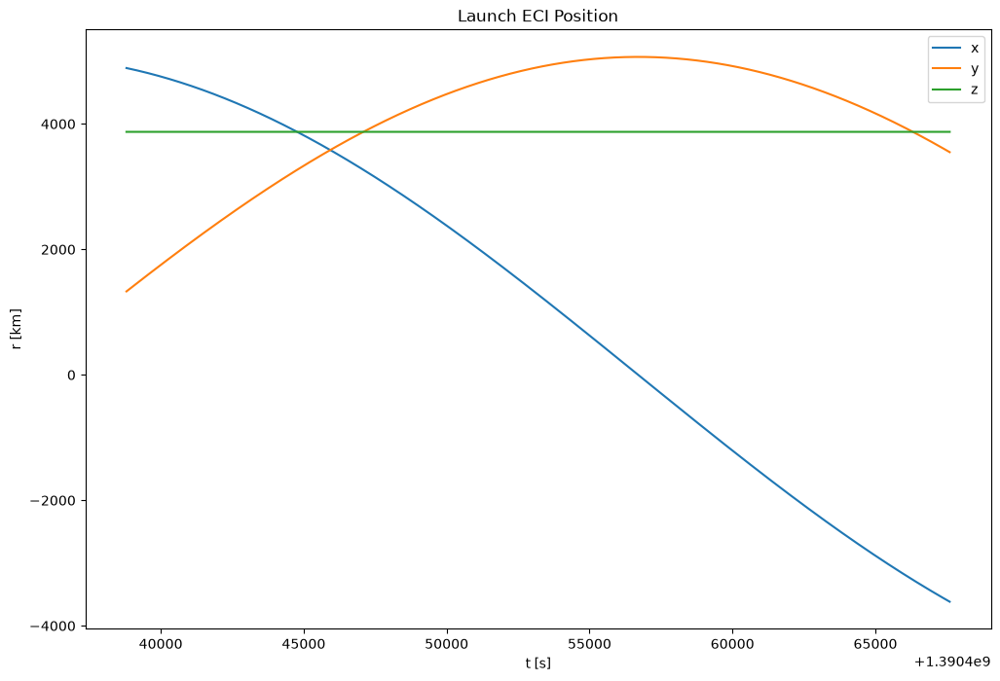

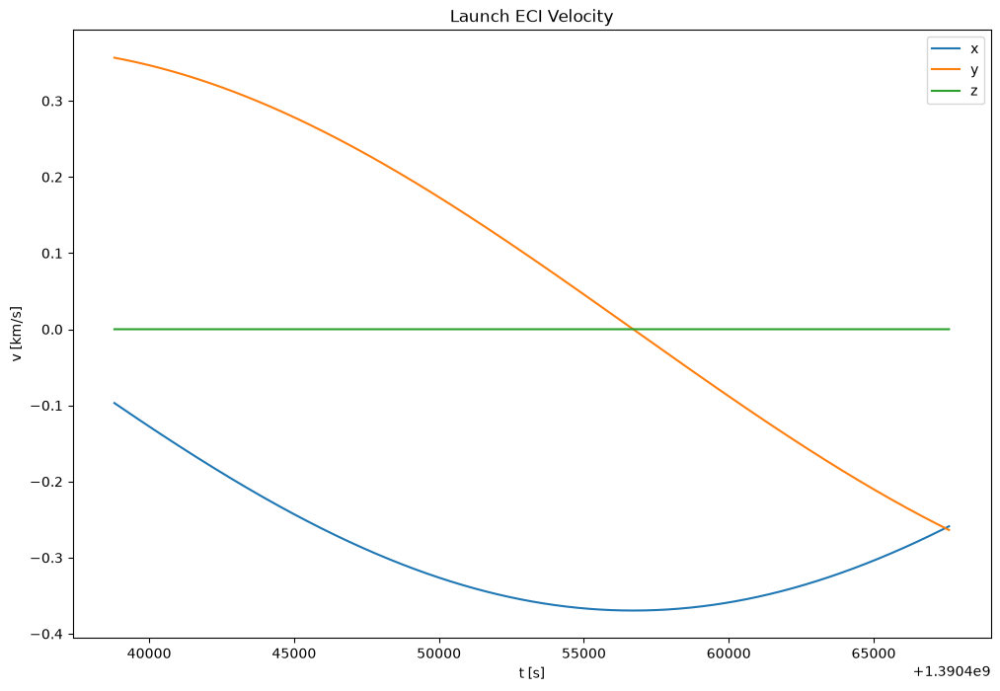

In [61]:
from orbital import launch_pci

launch_r_eci, launch_v_eci = launch_pci(t_total_utc, launch_lat, launch_lon, launch_alt,
                                        theta_ref = theta_utc_2014, t_ref = t_utc_2014)

plt.figure(figsize=(12,8))
plt.title("Launch ECI Position")
plt.xlabel("t [s]")
plt.ylabel("r [km]")
plt.plot(t_total_utc, launch_r_eci[:,0], label = "x")
plt.plot(t_total_utc, launch_r_eci[:,1], label = "y")
plt.plot(t_total_utc, launch_r_eci[:,2], label = "z")
plt.legend()
plt.show()

plt.figure(figsize=(12,8))
plt.title("Launch ECI Velocity")
plt.xlabel("t [s]")
plt.ylabel("v [km/s]")
plt.plot(t_total_utc, launch_v_eci[:,0], label = "x")
plt.plot(t_total_utc, launch_v_eci[:,1], label = "y")
plt.plot(t_total_utc, launch_v_eci[:,2], label = "z")
plt.legend()
plt.show()

In [62]:
plot_3d(
    launch_r_eci,
    t_total_utc,
    labels="Launcher",
    bodies={"name": "Earth", "radius": R_EARTH},
    title="3D Launch Site Position"
)

### Sat positions

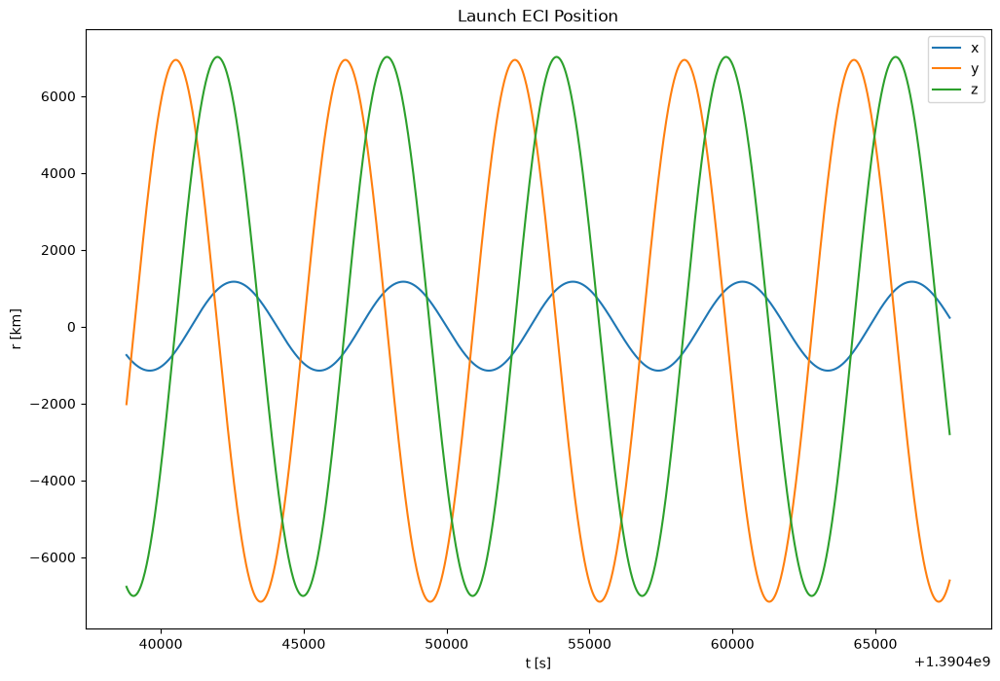

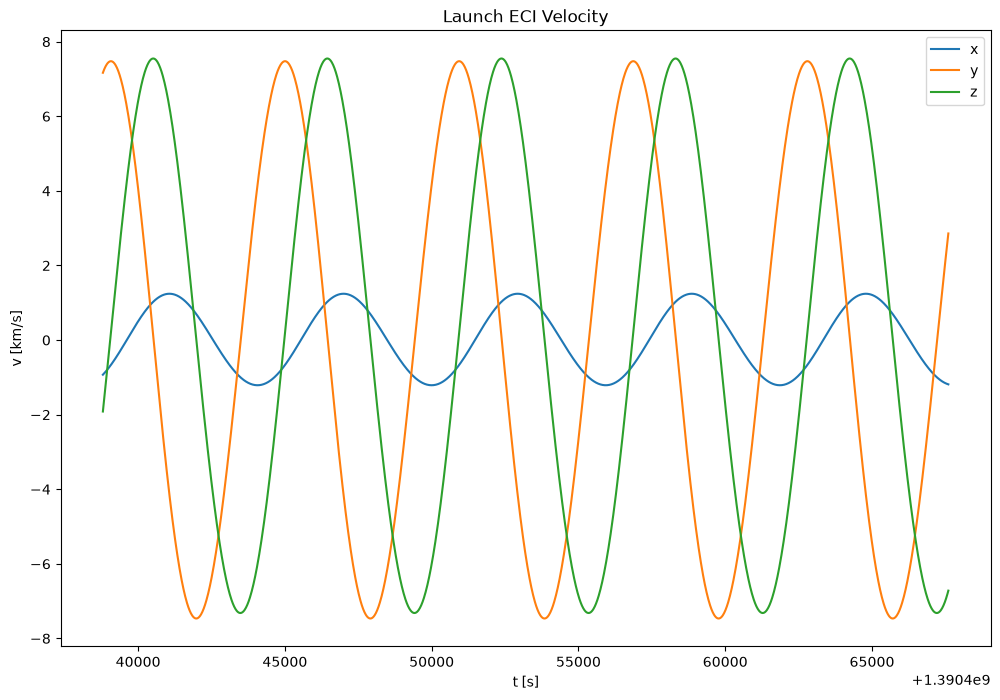

In [39]:
## Sat functions
def dove3_rv_eci(t_arr, t0 = dove_epoch_utc) -> np.ndarray | tuple[np.ndarray, np.ndarray]:
    # M_new = (M_dove + n_dove*(t_arr - t0))
    M_new = np.mod(
        M_dove + n_dove*(t_arr - t0), 2*np.pi
    )
    rv = np.array([rv_from_coe(a_dove,e_dove,i_dove,raan_dove,aop_dove,M,MU_EARTH) for M in M_new])
    r = rv[:,0,:]
    v = rv[:,1,:]
    return r,v

dove3_r_eci, dove3_v_eci = dove3_rv_eci(t_total_utc)

plt.figure(figsize=(12,8))
plt.title("Launch ECI Position")
plt.xlabel("t [s]")
plt.ylabel("r [km]")
plt.plot(t_total_utc, dove3_r_eci[:,0], label = "x")
plt.plot(t_total_utc, dove3_r_eci[:,1], label = "y")
plt.plot(t_total_utc, dove3_r_eci[:,2], label = "z")
plt.legend()
plt.show()

plt.figure(figsize=(12,8))
plt.title("Launch ECI Velocity")
plt.xlabel("t [s]")
plt.ylabel("v [km/s]")
plt.plot(t_total_utc, dove3_v_eci[:,0], label = "x")
plt.plot(t_total_utc, dove3_v_eci[:,1], label = "y")
plt.plot(t_total_utc, dove3_v_eci[:,2], label = "z")
plt.legend()
plt.show()

### Both positions

In [63]:
plot_3d(
    [launch_r_eci, dove3_r_eci],
    t_total_utc,
    labels=["Launcher", "Dove 3"],
    bodies={"name": "Earth", "radius": R_EARTH},
    title="3D Launch Site Position"
)

### Calculation

In [41]:
# Search space
dv1_arr = np.full((N_LAUNCHES, N_TOFS), np.nan)
dv2_arr = np.full((N_LAUNCHES, N_TOFS), np.nan)
collision_arr = np.full((N_LAUNCHES, N_TOFS), np.nan)
hyper_para_arr = np.full((N_LAUNCHES, N_TOFS), np.nan)
err_arr = np.full((N_LAUNCHES, N_TOFS), np.nan)
print(f"Search space: {dv1_arr.shape}, with {N_LAUNCHES * N_TOFS} total")

Search space: (1441, 481), with 693121 total


In [42]:
# def find_launch_rv(t,t_arr,r_arr,v_arr):
#     i = np.argmin(np.abs(t_arr - t))
#     return r_arr[i], v_arr[i]

def find_rv(t, t_arr, r_arr, v_arr):
    i = np.searchsorted(t_arr, t)
    assert np.isclose(t_arr[i], t)
    return r_arr[i], v_arr[i]

for launch_num in tqdm(range(N_LAUNCHES)):
    t_launch = t_arr_launch[launch_num]
    # print(f"Launch offset: {t_launch}")
    for tof_num in range(N_TOFS):
        tof = t_arr_tofs[tof_num]
        t_intercept = t_launch + tof
        # print(f"\tIntercept time: {t_intercept}")
        
        
        r_launch, v_launch = find_rv(t_launch + sim_start_utc, t_total_utc, launch_r_eci, launch_v_eci)
        r_sat, v_sat = find_rv(t_intercept + sim_start_utc, t_total_utc, dove3_r_eci, dove3_v_eci)
        
        # Parabola/hyperbola check (short way)
        c = norm(r_launch - r_sat)
        s = (norm(r_launch) + norm(r_sat) + c) / 2
        dt_parabola = 1/3 * np.sqrt(2/MU_EARTH) * (s**(3/2) - (s-c)**(3/2))
        if tof <= dt_parabola:
            hyper_para_arr[launch_num, tof_num] = 1
            continue
        
        # Call solver
        try:
            cross_z = np.cross(r_launch, r_sat)[2]

            # Allows satellite to go retrograde if it is "behind"/west of the launch site
            prograde = cross_z >= 0

            v1, v2 = vallado2013(
                MU_EARTH,
                r_launch,
                r_sat,
                tof,
                # M=1,  # No multi-orbit solutions
                prograde=prograde,
                low_path=True                   # short way
            )
        except ValueError:
            err_arr[launch_num, tof_num] = 1
            continue
        

        # Earth-impact check
        if np.dot(r_launch, v1) < 0 and np.dot(r_sat, v2) > 0:
            e_sp = 1/2 * norm(v1)**2 - MU_EARTH / norm(r_launch)
            a = -MU_EARTH / 2 / e_sp
            h = norm(np.cross(r_launch, v1))
            p = h*h/MU_EARTH
            e = np.sqrt((a-p)/a)
            r_p = a*(1-e)
            
            if r_p <= R_EARTH:
                collision_arr[launch_num, tof_num] = 1
                continue
        
        dv1 = norm(v1 - v_launch)
        dv2 = norm(v_sat - v2)
        # print()
        
        
            
        dv1_arr[launch_num, tof_num] = dv1
        dv2_arr[launch_num, tof_num] = dv2

dv_arr = dv1_arr + dv2_arr

100%|██████████| 1441/1441 [02:56<00:00,  8.14it/s]


## Part c/d

In [43]:

fig = go.Figure()

# plotly expects [y_dim, x_dim] so z.T
fig.add_trace(go.Heatmap(
    x=t_arr_launch / MIN_TO_SEC,
    y=t_arr_tofs / MIN_TO_SEC,
    z=dv1_arr.T,
    colorscale="Viridis",
    colorbar=dict(title="Departure dv [km/s]"),
    showscale=False,
    opacity=0.8,
))

fig.add_trace(go.Contour(
    x=t_arr_launch / MIN_TO_SEC,
    y=t_arr_tofs / MIN_TO_SEC,
    z=dv1_arr.T,

    contours=dict(
        # start=3.5,
        # end=12,
        # size=0.5,
        coloring="fill",
        showlabels=True,
    ),

    line=dict(
        width=1,
        smoothing=1.3
    ),

    colorscale="Viridis",
    colorbar=dict(title="Departure dv [km/s]"),
))


# fig.add_trace(go.Scatter(
#     x=launch_grid.ravel(),
#     y=tof_grid.ravel(),
#     mode="markers",
#     marker=dict(
#         size=4,
#         color="black",
#         opacity=0.7
#     ),
#     name="Grid points"
# ))

fig.update_layout(
    title="Total dV for intercept",
    xaxis_title="Launch time after sim start [min]",
    yaxis_title="Time of flight [min]",
    width=1200,
    height=700
)

fig.update_xaxes(
    range=[np.min(t_arr_launch / MIN_TO_SEC), np.max(t_arr_launch / MIN_TO_SEC)],
    constrain="domain"
)

fig.update_yaxes(
    range=[np.min(t_arr_tofs / MIN_TO_SEC), np.max(t_arr_tofs / MIN_TO_SEC)],
    constrain="domain"
)

fig.write_image("hw3_plots_test/15_sec_total_dv_plot.png", width=2000, height=1200, scale=2)


fig.show()

In [44]:
print("The dv plot seems to have a period of about 90 minutes (typical of a LEO satellite). ")
print("The dv in the center of its bulbs also decreases as time goes on.")

The dv plot seems to have a period of about 90 minutes (typical of a LEO satellite). 
The dv in the center of its bulbs also decreases as time goes on.


In [45]:

fig = go.Figure()

# plotly expects [y_dim, x_dim] so z.T
fig.add_trace(go.Heatmap(
    x=t_arr_launch / MIN_TO_SEC,
    y=t_arr_tofs / MIN_TO_SEC,
    z=dv_arr.T,
    colorscale="Viridis",
    colorbar=dict(title="Departure dv [km/s]"),
    showscale=False,
    opacity=0.8,
))

fig.add_trace(go.Contour(
    x=t_arr_launch / MIN_TO_SEC,
    y=t_arr_tofs / MIN_TO_SEC,
    z=dv_arr.T,

    contours=dict(
        # start=3.5,
        # end=12,
        # size=0.5,
        coloring="fill",
        showlabels=True,
    ),

    line=dict(
        width=1,
        smoothing=1.3
    ),

    colorscale="Viridis",
    colorbar=dict(title="Departure dv [km/s]"),
))


# fig.add_trace(go.Scatter(
#     x=launch_grid.ravel(),
#     y=tof_grid.ravel(),
#     mode="markers",
#     marker=dict(
#         size=4,
#         color="black",
#         opacity=0.7
#     ),
#     name="Grid points"
# ))

fig.update_layout(
    title="Total dV for rendezvous",
    xaxis_title="Launch time after sim start [min]",
    yaxis_title="Time of flight [min]",
    width=1200,
    height=700
)

fig.update_xaxes(
    range=[np.min(t_arr_launch / MIN_TO_SEC), np.max(t_arr_launch / MIN_TO_SEC)],
    constrain="domain"
)

fig.update_yaxes(
    range=[np.min(t_arr_tofs / MIN_TO_SEC), np.max(t_arr_tofs / MIN_TO_SEC)],
    constrain="domain"
)

fig.write_image("hw3_plots_test/15_sec_rpo_dv_plot.png", width=2000, height=1200, scale=2)


fig.show()

In [46]:
print("Looks very similar to the intercept plot, but there are clear diagonal lines that have a lot of dv.")
print("The total dv required in the center of the bulbs also decreases each period.")
print("The lines where the solution becomes invalid (intercepts Earch or parabolic/hyperbolic) are almost vertical close to the minimum dv.")
print("This is likely because the optimal trajectory goes North slowly near the satellite's path, so delaying even a bit more will cause it to miss entirely.")

Looks very similar to the intercept plot, but there are clear diagonal lines that have a lot of dv.
The total dv required in the center of the bulbs also decreases each period.
The lines where the solution becomes invalid (intercepts Earch or parabolic/hyperbolic) are almost vertical close to the minimum dv.
This is likely because the optimal trajectory goes North slowly near the satellite's path, so delaying even a bit more will cause it to miss entirely.


## Part e/f

### 3D Optimal Plots

In [47]:
# Finding min

def min_dv(dv_grid, launch_grid, tof_grid):
    dv_min = np.nanmin(dv_grid)
    idx_grid = np.nanargmin(dv_grid)
    launch_idx, tof_idx = np.unravel_index(idx_grid, dv_grid.shape)
    
    return dv_min, launch_grid[launch_idx, tof_idx], tof_grid[launch_idx, tof_idx]

dv_min_int, launch_delay_int_s, tof_int_s = min_dv(dv1_arr, launch_grid, tof_grid)
print(f"Min dv for intercept:\n\t{dv_min_int:.3f} km/s at delay of {launch_delay_int_s / MIN_TO_SEC} min and tof of {tof_int_s / MIN_TO_SEC} min")

dv_min_rpo, launch_delay_rpo_s, tof_rpo_s = min_dv(dv_arr, launch_grid, tof_grid)
print(f"Min dv for rendezvous:\n\t{dv_min_rpo:.3f} km/s at delay of {launch_delay_rpo_s / MIN_TO_SEC} min and tof of {tof_rpo_s / MIN_TO_SEC} min")

Min dv for intercept:
	3.860 km/s at delay of 326.0 min and tof of 8.75 min
Min dv for rendezvous:
	8.984 km/s at delay of 333.75 min and tof of 19.75 min


In [48]:
print("It could be less than the circular velocity because the launcher has an initial velocity due to the rotation of the Earth")

It could be less than the circular velocity because the launcher has an initial velocity due to the rotation of the Earth


In [49]:
# Optimal trajectory intercept

def two_body(t,x,mu=MU_EARTH):
    del t
    r,v = x[0:3], x[3:6]
    a = -mu / norm(r)**3 * r
    return np.concat((v,a))

def propagate_traj(launch_delay_s, tof_s):
    r_launch, _ = find_rv(launch_delay_s + sim_start_utc, t_total_utc, launch_r_eci, launch_v_eci)
    r_sat, _ = find_rv(tof_s + launch_delay_s + sim_start_utc, t_total_utc, dove3_r_eci, dove3_v_eci)

    cross_z = np.cross(r_launch, r_sat)[2]
    prograde = cross_z >= 0

    v1, _ = vallado2013(
        MU_EARTH,
        r_launch,
        r_sat,
        tof_s,
        prograde=prograde,
        low_path=True                   # short way
    )

    t_optimal_propagation_arr = np.linspace(0, tof_s, 1000)

    sol_intercept: np.ndarray = solve_ivp(two_body, (0, tof_s), np.concatenate((r_launch, v1)), method='LSODA', t_eval=t_optimal_propagation_arr, rtol=1e-6, atol=1e-9)
    
    opt_t_utc = sim_start_utc + launch_delay_s + sol_intercept.t
    return opt_t_utc, sol_intercept.y

opt_int_t_utc, opt_int_r_arr = propagate_traj(launch_delay_int_s, tof_int_s)
opt_rpo_t_utc, opt_rpo_r_arr = propagate_traj(launch_delay_rpo_s, tof_rpo_s)

In [52]:
plot_3d([launch_r_eci, dove3_r_eci, opt_int_r_arr[0:3,:].T], [t_total_utc, t_total_utc, opt_int_t_utc], ["Launcher", "Dove 3", "Optimal Trajectory"], bodies={"name": "Earth", "radius": R_EARTH}, title="Intercept Optimal trajectory", t_max = opt_int_t_utc[-1])

In [53]:
plot_3d([launch_r_eci, dove3_r_eci, opt_rpo_r_arr[0:3,:].T], [t_total_utc, t_total_utc, opt_rpo_t_utc], ["Launcher", "Dove 3", "Optimal Trajectory"],bodies={"name": "Earth", "radius": R_EARTH}, title="Rendezvous Optimal Trajectory", t_max = opt_rpo_t_utc[-1])

## Part g/h

In [54]:
MAX_DV = 5 # km/s

dv_limited = dv1_arr.copy()
dv_limited[dv_limited > MAX_DV] = np.nan

In [55]:
def earliest_time_dv(dv_grid, launch_grid, tof_grid):
    intercept_grid = (launch_grid + tof_grid).astype(float)
    intercept_grid[np.isnan(dv_grid)] = np.nan
    intercept_idx = np.nanargmin(intercept_grid)
    launch_idx, tof_idx = np.unravel_index(intercept_idx, intercept_grid.shape)
    
    dv_min = dv_grid[launch_idx, tof_idx]
    
    return dv_min, launch_grid[launch_idx, tof_idx], tof_grid[launch_idx, tof_idx]

def smallest_tof_dv(dv_grid, launch_grid, tof_grid):
    new_tof_grid = tof_grid.copy().astype(float)
    new_tof_grid[np.isnan(dv_grid)] = np.nan
    idx = np.nanargmin(new_tof_grid)
    launch_idx, tof_idx = np.unravel_index(idx, intercept_grid.shape)
    
    dv_min = dv_grid[launch_idx, tof_idx]
    
    return dv_min, launch_grid[launch_idx, tof_idx], tof_grid[launch_idx, tof_idx]


dv_early, launch_delay_early, tof_delay_early = earliest_time_dv(dv_limited, launch_grid, tof_grid)
print(f"Quickest intercept at:\n\t{(launch_delay_early + tof_delay_early) / MIN_TO_SEC} min with delay of {launch_delay_early / MIN_TO_SEC}, tof of {tof_delay_early / MIN_TO_SEC} min, and dv of {dv_early:.3f} km/s")

dv_small_tof, launch_delay_small_tof, tof_delay_small_tof = smallest_tof_dv(dv_limited, launch_grid, tof_grid)
print(f"Smallest tof at:\n\t{(launch_delay_small_tof + tof_delay_small_tof) / MIN_TO_SEC} min with delay of {launch_delay_small_tof / MIN_TO_SEC}, tof of {tof_delay_small_tof / MIN_TO_SEC} min, and dv of {dv_small_tof:.3f} km/s")

Quickest intercept at:
	232.25 min with delay of 216.25, tof of 16.0 min, and dv of 4.999 km/s
Smallest tof at:
	334.25 min with delay of 329.75, tof of 4.5 min, and dv of 4.929 km/s


In [56]:
from datetime import datetime, timezone
# In UTC

dt_early_launch_utc = datetime.fromtimestamp(launch_delay_early + sim_start_utc, tz=timezone.utc)
print(f"Launch time for quickest intercept:\n\t{dt_early_launch_utc} ({dt_early_launch_utc.timestamp()} in unix)")

dt_smallest_tof_launch_utc = datetime.fromtimestamp(launch_delay_small_tof + sim_start_utc, tz=timezone.utc)
print(f"Launch time for smallest time of flight:\n\t{dt_smallest_tof_launch_utc} ({dt_smallest_tof_launch_utc.timestamp()} in unix)")

Launch time for quickest intercept:
	2014-01-23 04:36:15+00:00 (1390451775.0 in unix)
Launch time for smallest time of flight:
	2014-01-23 06:29:45+00:00 (1390458585.0 in unix)


In [57]:
fig = go.Figure()

fig.add_trace(go.Heatmap(
    x=t_arr_launch / MIN_TO_SEC,
    y=t_arr_tofs / MIN_TO_SEC,
    z=dv_limited.T,
    colorscale="Viridis",
    colorbar=dict(title="Departure dv [km/s]"),
    opacity=0.8
))

# fig.add_trace(go.Contour(
#     x=t_arr_launch / MIN_TO_SEC,
#     y=t_arr_tofs / MIN_TO_SEC,
#     z=intercept_grid.T / MIN_TO_SEC,
#     autocontour=False,
#     showscale=False,
#     showlegend=False,
#     line=dict(width=2, color="black"),
#     colorscale=[
#         [0, "blue"],
#         [1, "blue"]
#     ],

#     contours=dict(
#         coloring="lines",
#         showlabels=True,
#         start=(launch_delay_early + tof_delay_early)/MIN_TO_SEC,
#         end=(launch_delay_early + tof_delay_early)/MIN_TO_SEC,
#         labelfont=dict(size=10, color="black"),
#     ),
# ))

# fig.add_trace(go.Scatter(
#     x=[None], y=[None],
#     mode="lines",
#     line=dict(color="blue", width=2),
#     name=f"Minimum intercept time ({int((launch_delay_early + tof_delay_early) / MIN_TO_SEC)} min)"
# ))


# fig.add_trace(go.Contour(
#     x=t_arr_launch / MIN_TO_SEC,
#     y=t_arr_tofs / MIN_TO_SEC,
#     z=tof_grid.T / MIN_TO_SEC,
#     autocontour=False,
#     showscale=False,
#     showlegend=False,
#     line=dict(width=2, color="black"),
#     colorscale=[
#         [0, "orange"],
#         [1, "orange"]
#     ],

#     contours=dict(
#         coloring="lines",
#         showlabels=True,
#         start=tof_delay_small_tof / MIN_TO_SEC,
#         end=tof_delay_small_tof / MIN_TO_SEC,
#         labelfont=dict(size=10, color="black"),
#     ),
# ))


# fig.add_trace(go.Scatter(
#     x=[None], y=[None],
#     mode="lines",
#     line=dict(color="orange", width=2),
#     name=f"Minimum time of flight ({int(tof_delay_small_tof / MIN_TO_SEC)} min)"
# ))

# Vibes
# fig.update_xaxes(
#     range=[200, 340],
#     constrain="domain"
# )

# fig.update_yaxes(
#     range=[3, 25],
#     constrain="domain"
# )

# fig.add_trace(go.Scatter(
#     # x=[launch_delay_early/MIN_TO_SEC],
#     # y=[tof_delay_early/MIN_TO_SEC],
#     x=[launch_delay_small_tof/MIN_TO_SEC],
#     y=[tof_delay_small_tof/MIN_TO_SEC],
#     mode="markers",
#     marker=dict(
#         symbol="x",
#         size=10,
#         color="red",
#     ),
#     name="Optimal point"
# ))

fig.update_layout(
    # title="Intercept with earliest time with dV < 5 km/s",
    # title="Intercept with smallest tof with dV < 5 km/s",
    title="dV < 5 km/s",
    xaxis_title="Launch time after sim start [min]",
    yaxis_title="Time of flight [min]",
    width=1200,
    height=700,
    legend=dict(
        x=0.02,
        y=0.98,
        xanchor="left",
        yanchor="top"
    )
)
# fig.write_image(f"hw3_plots/earliest_intercept_5_sec.png", width=2000, height=1200, scale=2)
# fig.write_image("hw3_plots_test/smallest_tof_5_sec.png", width=2000, height=1200, scale=2)
fig.write_image("hw3_plots_test/earliest_smallest_15_sec.png", width=2000, height=1200, scale=2)

fig.show()